# Fakeddit Multimodal Misinformation Detection
### Stage 1 — Data Prep, Reproducible Subsampling & Text-Only Calibrated Baseline

**Project:** Multimodal fake-news detection with confidence calibration.

**This notebook covers:**
1. Download Fakeddit metadata (TSVs only — no images yet)
2. Load, inspect, and clean the multimodal-only samples
3. Create a **fixed, reproducible stratified subsample** (this is the sample you'll reuse across every later stage of this project — CLIP embeddings, fusion, calibration, explainability all build on the exact same IDs)
4. Quick dead-link check on image URLs (to plan the image pipeline's download buffer — no images downloaded or stored yet)
5. Text-only RoBERTa baseline
6. Evaluation: Accuracy, Macro-F1, AUROC — **plus Expected Calibration Error (ECE) and a reliability diagram**


## Step 0 — Setup

In [ ]:
!pip install -q transformers sentencepiece scikit-learn matplotlib pandas requests tqdm gdown joblib


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import requests

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Project root on Drive — mirrors your mami_2022 folder pattern
DRIVE_ROOT = '/content/drive/MyDrive/fakeddit_calibration'
for sub in ['metadata', 'embeddings', 'models', 'figures']:
    os.makedirs(f'{DRIVE_ROOT}/{sub}', exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
print(f"Drive root: {DRIVE_ROOT}")


Mounted at /content/drive
Using device: cpu
Drive root: /content/drive/MyDrive/fakeddit_calibration


## Step 1 — Download Fakeddit metadata (TSVs only, no images)




In [ ]:
import gdown

FILE_IDS = {
    'multimodal_train.tsv': '1XsOkD3yhxgWu8URMes0S9LVSwuFJ4pT6',
    'multimodal_validate.tsv': '1Z99QrwpthioZQY2U6HElmnx8jazf7-Kv',
    'multimodal_test_public.tsv': '1p9EewIKVcFbipVRLZNGYc2JbSC7A0SWv',
}

for fname, file_id in FILE_IDS.items():
    out_path = f'{DRIVE_ROOT}/metadata/{fname}'
    if os.path.exists(out_path):
        print(f"Already downloaded: {fname}")
        continue
    if 'PASTE' in file_id:
        print(f"Fill in the real file ID for {fname} before running this cell.")
        continue
    gdown.download(f'https://drive.google.com/uc?id={file_id}', out_path, quiet=False)


Already downloaded: multimodal_train.tsv
Already downloaded: multimodal_validate.tsv
Already downloaded: multimodal_test_public.tsv


## Step 2 — Load and inspect

Load all three splits, concatenate for now (we'll make our own stratified split in Step 3 rather than relying on the original train/val/test division, this keeps our subsample self-contained and reproducible).


In [ ]:
dfs = []
for fname in ['multimodal_train.tsv', 'multimodal_validate.tsv', 'multimodal_test_public.tsv']:
    path = f'{DRIVE_ROOT}/metadata/{fname}'
    if os.path.exists(path):
        d = pd.read_csv(path, sep='\t')
        d['source_split'] = fname
        dfs.append(d)
        print(f"{fname}: {len(d)} rows")

df = pd.concat(dfs, ignore_index=True)
print(f"\nTotal rows: {len(df)}")
print(f"Columns: {list(df.columns)}")
df.head()


multimodal_train.tsv: 564000 rows
multimodal_validate.tsv: 59342 rows
multimodal_test_public.tsv: 59319 rows

Total rows: 682661
Columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label', 'source_split']


,author,clean_title,created_utc,domain,hasImage,id,image_url,linked_submission_id,num_comments,score,subreddit,title,upvote_ratio,2_way_label,3_way_label,6_way_label,source_split
0,Alexithymia,my walgreens offbrand mucinex was engraved wit...,1.551641e+09,i.imgur.com,True,awxhir,https://external-preview.redd.it/WylDbZrnbvZdB...,NaN,2.0,12,mildlyinteresting,My Walgreens offbrand Mucinex was engraved wit...,0.84,1,0,0,multimodal_train.tsv
1,VIDCAs17,this concerned sink with a tiny hat,1.534727e+09,i.redd.it,True,98pbid,https://preview.redd.it/wsfx0gp0f5h11.jpg?widt...,NaN,2.0,119,pareidolia,This concerned sink with a tiny hat,0.99,0,2,2,multimodal_train.tsv
2,prometheus1123,hackers leak emails from uae ambassador to us,1.496511e+09,aljazeera.com,True,6f2cy5,https://external-preview.redd.it/6fNhdbc6K1vFA...,NaN,1.0,44,neutralnews,Hackers leak emails from UAE ambassador to US,0.92,1,0,0,multimodal_train.tsv
3,NaN,puppy taking in the view,1.471341e+09,i.imgur.com,True,4xypkv,https://external-preview.redd.it/HLtVNhTR6wtYt...,NaN,26.0,250,photoshopbattles,PsBattle: Puppy taking in the view,0.95,1,0,0,multimodal_train.tsv
4,3rikR3ith,i found a face in my sheet music too,1.525318e+09,i.redd.it,True,8gnet9,https://preview.redd.it/ri7ut2wn8kv01.jpg?widt...,NaN,2.0,13,pareidolia,I found a face in my sheet music too!,0.84,0,2,2,multimodal_train.tsv


In [ ]:
# Keep only rows with both text and an image URL, and drop obvious junk
df = df.dropna(subset=['clean_title', 'image_url']).copy()
df = df[df['clean_title'].str.strip().str.len() > 0]
df = df.drop_duplicates(subset=['id']).reset_index(drop=True)

print(f"Rows after cleaning: {len(df)}")
print("\n3-way label distribution:")
print(df['3_way_label'].value_counts())


Rows after cleaning: 680798

3-way label distribution:
3_way_label
2    396517
0    267601
1     16680
Name: count, dtype: int64


## Step 3 — Fixed, reproducible stratified subsample

This is the single most important cell in the whole project: the IDs selected here are what every later stage (CLIP embeddings, fusion, calibration, explainability) will be built on.

Using **3-way labels** — granular enough to produce interesting boundary/uncertain cases for the calibration analysis, without the heavier label noise of the 6-way scheme.

Target: ~30,000 samples, split 70/15/15 into train/val/test.


In [ ]:
N_SAMPLES = 30000
LABEL_COL = '3_way_label'

subsample_path = f'{DRIVE_ROOT}/metadata/subsample_30k.csv'

if os.path.exists(subsample_path):
    print("Subsample already exists — loading cached version (NOT regenerating).")
    sub_df = pd.read_csv(subsample_path)
else:
    sub_df, _ = train_test_split(
        df, train_size=N_SAMPLES, stratify=df[LABEL_COL], random_state=SEED
    )
    sub_df = sub_df.reset_index(drop=True)
    sub_df.to_csv(subsample_path, index=False)
    print(f"Created and saved new subsample: {len(sub_df)} rows -> {subsample_path}")

print("\nLabel distribution in subsample:")
print(sub_df[LABEL_COL].value_counts(normalize=True).round(3))


Subsample already exists — loading cached version (NOT regenerating).

Label distribution in subsample:
3_way_label
2    0.582
0    0.393
1    0.024
Name: proportion, dtype: float64


In [ ]:
# 70/15/15 split within the subsample

splits_dir = f'{DRIVE_ROOT}/metadata/splits'
os.makedirs(splits_dir, exist_ok=True)

train_path = f'{splits_dir}/train.csv'
val_path   = f'{splits_dir}/val.csv'
test_path  = f'{splits_dir}/test.csv'

if all(os.path.exists(p) for p in [train_path, val_path, test_path]):
    print("Splits already exist — loading cached versions.")
    train_df = pd.read_csv(train_path)
    val_df   = pd.read_csv(val_path)
    test_df  = pd.read_csv(test_path)
else:
    train_df, temp_df = train_test_split(
        sub_df, test_size=0.30, stratify=sub_df[LABEL_COL], random_state=SEED
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df[LABEL_COL], random_state=SEED
    )
    train_df.to_csv(train_path, index=False)
    val_df.to_csv(val_path, index=False)
    test_df.to_csv(test_path, index=False)
    print("Created and saved train/val/test splits.")

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")


Splits already exist — loading cached versions.
Train: 21000  Val: 4500  Test: 4500


## Step 4 — Quick dead-link check

A Reddit-sourced dataset from 2020 will have a meaningful fraction of dead image URLs by now (deleted posts, expired imgur links, etc). Before the image pipeline's full download-embed-delete step, a **lightweight HEAD-request check** on a small random sample to estimate the dead-link rate, this will tell whether to oversample now or accept a smaller effective dataset later.


In [ ]:
def check_url_alive(url, timeout=4):
    try:
        r = requests.head(url, timeout=timeout, allow_redirects=True)
        return r.status_code == 200
    except requests.RequestException:
        return False

check_sample = sub_df.sample(n=200, random_state=SEED)
results = [check_url_alive(u) for u in tqdm(check_sample['image_url'], desc='Checking URLs')]

alive_rate = sum(results) / len(results)
print(f"Estimated alive rate: {alive_rate:.1%}")
print(f"Estimated dead rate:  {1 - alive_rate:.1%}")
print(f"\nIf this holds across the full subsample, expect ~{int(len(sub_df) * alive_rate)} usable image-bearing rows for the image pipeline.")
print("If the alive rate is well under 80%, consider increasing N_SAMPLES in Step 3 to compensate.")


Checking URLs:   0%|          | 0/200 [00:00<?, ?it/s]

Estimated alive rate: 68.0%
Estimated dead rate:  32.0%

If this holds across the full subsample, expect ~20400 usable image-bearing rows for the image pipeline.
If the alive rate is well under 80%, consider increasing N_SAMPLES in Step 3 to compensate.


## Step 5 — Text-only baseline: RoBERTa embeddings

Extract 768-d CLS embeddings from `roberta-base`, cached to Drive


In [ ]:
from transformers import RobertaTokenizer, RobertaModel

tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
roberta = RobertaModel.from_pretrained('roberta-base').to(device).eval()

@torch.no_grad()
def extract_roberta_embeddings(texts, batch_size=32):
    embeddings = []
    for i in tqdm(range(0, len(texts), batch_size), desc='Extracting RoBERTa embeddings'):
        batch = texts[i:i + batch_size]
        enc = tokenizer(list(batch), padding=True, truncation=True, max_length=128, return_tensors='pt').to(device)
        out = roberta(**enc)
        cls_emb = out.last_hidden_state[:, 0, :].cpu().numpy()  # CLS token, 768-d
        embeddings.append(cls_emb)
    return np.concatenate(embeddings, axis=0)

def get_or_create_embeddings(split_df, split_name):
    path = f'{DRIVE_ROOT}/embeddings/roberta_{split_name}.npy'
    if os.path.exists(path):
        print(f"Loading cached {split_name} embeddings.")
        return np.load(path)
    emb = extract_roberta_embeddings(split_df['clean_title'].tolist())
    np.save(path, emb)
    print(f"Saved {split_name} embeddings: {emb.shape} -> {path}")
    return emb

X_train = get_or_create_embeddings(train_df, 'train')
X_val   = get_or_create_embeddings(val_df, 'val')
X_test  = get_or_create_embeddings(test_df, 'test')

y_train = train_df[LABEL_COL].values
y_val   = val_df[LABEL_COL].values
y_test  = test_df[LABEL_COL].values


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading cached train embeddings.
Loading cached val embeddings.
Loading cached test embeddings.


## Step 6 — Train, evaluate, and calibrate

This step trains the classifier head, computes Accuracy / Macro-F1 / AUROC, and computes calibration (ECE + reliability diagram).

**Idempotency guarantee:** the first time this runs, it trains and saves everything (model, metrics, confusion matrix, calibration bins) to Drive. On every later run, including a full notebook restart, it detects the saved summary file and **loads those exact saved numbers instead of retraining**, so your results can never silently drift between runs. If you deliberately want to recompute (e.g. after changing the embeddings or subsample), delete `text_baseline_summary.json` on Drive first.


In [ ]:
def compute_ece(y_true, y_proba, n_bins=10):
    """Expected Calibration Error for multi-class predictions.
    Uses the predicted class's confidence vs whether that prediction was correct."""
    confidences = np.max(y_proba, axis=1)
    predictions = np.argmax(y_proba, axis=1)
    accuracies = (predictions == y_true).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_stats = []

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        in_bin = (confidences > lo) & (confidences <= hi)
        prop_in_bin = in_bin.mean()
        if prop_in_bin > 0:
            acc_in_bin = accuracies[in_bin].mean()
            conf_in_bin = confidences[in_bin].mean()
            ece += np.abs(acc_in_bin - conf_in_bin) * prop_in_bin
            bin_stats.append({'bin_range': [float(round(lo, 2)), float(round(hi, 2))],
                               'accuracy': float(acc_in_bin), 'confidence': float(conf_in_bin),
                               'proportion': float(prop_in_bin)})
    return float(ece), bin_stats


CLASSIFIER_PATH = f'{DRIVE_ROOT}/models/roberta_logreg_head.joblib'
SUMMARY_PATH = f'{DRIVE_ROOT}/metadata/text_baseline_summary.json'
FIGURE_PATH = f'{DRIVE_ROOT}/figures/text_baseline_reliability_diagram.png'

if os.path.exists(SUMMARY_PATH):
    print("Cached results found — loading saved metrics instead of retraining.")
    print("(Delete text_baseline_summary.json on Drive if you deliberately want to recompute.)\n")
    with open(SUMMARY_PATH) as f:
        summary = json.load(f)
    clf = joblib.load(CLASSIFIER_PATH)
    tb = summary['text_baseline']
    acc, macro_f1, auroc, ece = tb['accuracy'], tb['macro_f1'], tb['auroc'], tb['ece']
    bin_stats = tb['calibration_bins']
    conf_matrix = np.array(tb['confusion_matrix'])
else:
    print("No cached results found — training and evaluating now.\n")
    clf = LogisticRegression(max_iter=2000, random_state=SEED)
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)

    acc = float(accuracy_score(y_test, y_pred))
    macro_f1 = float(f1_score(y_test, y_pred, average='macro'))
    auroc = float(roc_auc_score(y_test, y_proba, multi_class='ovr'))
    conf_matrix = confusion_matrix(y_test, y_pred)
    ece, bin_stats = compute_ece(y_test, y_proba, n_bins=10)

    joblib.dump(clf, CLASSIFIER_PATH)
    summary = {
        'seed': SEED,
        'n_subsample': len(sub_df),
        'label_scheme': '3_way',
        'split_sizes': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
        'estimated_url_alive_rate': round(alive_rate, 4),
        'text_baseline': {
            'model': 'roberta-base (CLS embedding, 768-d) + LogisticRegression head',
            'accuracy': round(acc, 4),
            'macro_f1': round(macro_f1, 4),
            'auroc': round(auroc, 4),
            'ece': round(ece, 4),
            'calibration_bins': bin_stats,
            'confusion_matrix': conf_matrix.tolist(),
        }
    }
    with open(SUMMARY_PATH, 'w') as f:
        json.dump(summary, f, indent=2)
    print(f"Saved model -> {CLASSIFIER_PATH}")
    print(f"Saved summary -> {SUMMARY_PATH}")

print(f"\nAccuracy:  {acc:.4f}")
print(f"Macro-F1:  {macro_f1:.4f}")
print(f"AUROC:     {auroc:.4f}")
print(f"ECE:       {ece:.4f}")
print("\nConfusion matrix:")
print(conf_matrix)


No cached results found — training and evaluating now.

Saved model -> /content/drive/MyDrive/fakeddit_calibration/models/roberta_logreg_head.joblib
Saved summary -> /content/drive/MyDrive/fakeddit_calibration/metadata/text_baseline_summary.json

Accuracy:  0.7922
Macro-F1:  0.7045
AUROC:     0.9086
ECE:       0.0265

Confusion matrix:
[[1298    3  468]
 [  17   43   50]
 [ 393    4 2224]]


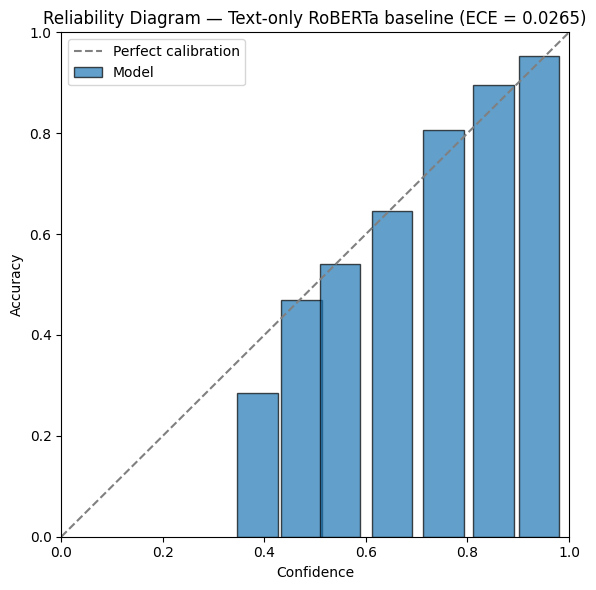

In [ ]:
# Reliability diagram

bin_confidences = [b['confidence'] for b in bin_stats]
bin_accuracies = [b['accuracy'] for b in bin_stats]

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
ax.bar(bin_confidences, bin_accuracies, width=0.08, alpha=0.7, edgecolor='black', label='Model')
ax.set_xlabel('Confidence')
ax.set_ylabel('Accuracy')
ax.set_title(f'Reliability Diagram — Text-only RoBERTa baseline (ECE = {ece:.4f})')
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()

if not os.path.exists(FIGURE_PATH):
    plt.savefig(FIGURE_PATH, dpi=150)
plt.show()
